# Résolution du modèle de McKendrick-Lotka et de l'équation de renouvellement en démographie

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## 1. Modèle de McKendrick-Lotka

### 1.2. Les éléments de description

- On va décrire l'évolution de la population par une fonction donnant la densité d'individu d'âge $a$ à l'instant $t$
$$
    x(a,t) \geq 0, \ \ \ \ \ a \in [0,a_{\max}], \ t \geq 0
$$
où $a_{\max}$ est l'âge maximal de la population, supposé fini.
- On introduit la fonction $\beta$ qui représente le taux de fertilité de la population en fonction de l'âge. On peut alors considérer le nombre total de nouveau né à l'instant $t$
$$
    B(t):= \int_{0}^{a_{\max}}\beta(a)x(a,t)d a
$$
- On introduit à présent la fonction $\mu$ qui représente le taux de mortalité de la population en fonction de l'âge.
- On définit ensuite la probabilité de survie, c'est-à-dire la probabilité pour qu'un nouveau né survive jusqu'à l'âge $a$
$$
    \Pi (a) := \exp\bigg(-\int_{0}^a \mu(\sigma)d \sigma\bigg)
$$
et on pose $\Pi(a_{\max}) = 0$ car on veut que pour un âge suffisament grand, ici $a_{\max}$, un individu n'ait aucune chance de survie.
- On définit de plus la fonction de maternité pour tout $a \in [0,a_{\max}]$
$$
    K(a) := \beta(a)\Pi(a)
$$
elle synthétise la dynamique des naissances et des décès de la population.
- Enfin, on définit le nombre de reproduction
$$
    R := \int_0^{a_{\max}} \beta(a)\Pi(a)d a = \int_0^{a_{\max}} K(a)d a
$$
il donne la moyenne du nombre de nouveau né qu'un individu produit au cours de sa vie. Ce paramètre jouera un rôle important dans le comportement asymptotique de la population. Intuitivement, si $R>1$ la population va augmenter et si $R<1$ la population va décroitre.

### 1.3. Modèle de McKendrick-Lotka

On considère le modèle de McKendrick-Lotka
$$
\left\{\begin{array}{l}
    \partial_a x(a,t) + \partial_t x(a,t) = -\mu(a)x(a,t) \\
    \\
    x(0,t) = B(t) = \displaystyle{\int_0^{a_{\max}}} \beta (a)x(a,t) d a \\
    \\
    x(a,0) = x_0(a)
\end{array}\right.
$$
où $x_0$ est la donnée initiale représentant le nombre d'individu d'âge $a$ à l'instant $t=0$ et la condition au bord donne le nombre de nouveau né à l'instant $t \in \mathbb{R}_+^*$.
\\
Au vu du contexte démographique, il est raisonnable de faire les hypothèses suivantes 
- $\beta \in L^{\infty}(0,a_{\max})$ et pour presque tout $a \in [0,a_{\max}]$, $0 \leq \beta(a) \leq \beta_+$ ;
- comme $\Pi(a_{\max}) = 0$, on pose
$$
    \int_0^{a_{\max}}\mu(\sigma) d \sigma = +\infty
$$
- $\mu \in L^1_{loc}(0,a_{\max})$ et pour presque tout $a \in [0,a_{\max}]$, $\mu(a) \geq 0$ ;
- $x_0 \in L^1(0,a_{\max})$ et pour presque tout $a \in [0,a_{\max}]$, $x_0(a) \geq 0$.

La solution obtenue par la méthode des caractéristiques est
$$x(a,t) = \left\{\begin{array}{lc}
    x_0(a - t)\dfrac{\Pi(a)}{\Pi(a-t)} & \text{ si } a \geq t, \\
    & \\
    B(t-a)\Pi(a) & \text{ si } a < t.
\end{array}\right.$$

### 1.3. Résolution numérique

Ici, on a choisi les fonctions suivantes
$$
\mu(a)=\frac{3a^3}{a_{\max}^3-a^3}
$$

$$
\Pi(a)=1-\left(\frac{a}{a_{\max}}\right)^3
$$

$$
\beta(a)=
\begin{cases}
0.045, & 20\leq a<40,\\
0, & \text{sinon}.
\end{cases}
$$

$$
K(a)=\Pi(a)\beta(a)
$$

$$
x_0(a)=1-\left(\frac{a}{a_{\max}}\right)^3
$$

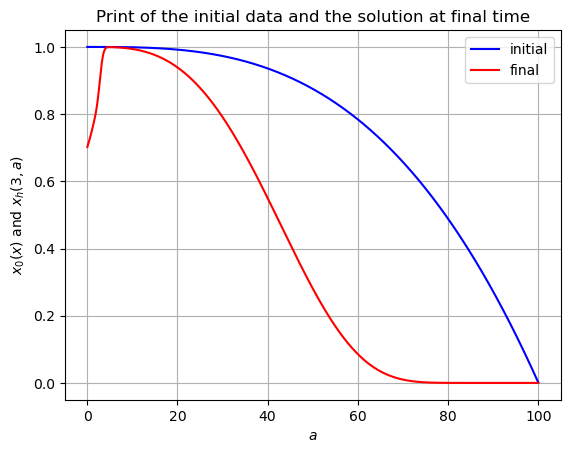

In [8]:
initial = np.loadtxt("mckendrick_lotka_solution_initial.txt")
final = np.loadtxt("mckendrick_lotka_solution_final.txt")

plt.plot(initial[:,0], initial[:,1], color = 'blue', label="initial")
plt.plot(final[:,0], final[:,1], color = 'red', label="final")
plt.xlabel("$a$")
plt.ylabel("$x_0(x)$ and $x_h(3, a)$")
plt.title("Print of the initial data and the solution at final time")
plt.grid()
plt.legend()
plt.show()

## 2. L'équation de renouvellement en démographie

### 2.1. L'équation de renouvellement

On peut réinjecter la solution $x$ dans la condition au bord. On obtient
$$B(t) =  \int_0^t K(a)B(t-a)d a + \int_0^{a_{\max}} \beta(a+t)x_0(a)\frac{\Pi(a+t)}{\Pi(a)} d a$$

### 2.2. Résolution numérique

On a les mêmes données que dans la section $1.3$. Ici, la solution $B$ est calculée de deux manières différentes, d'abord avec le schéma VF à l'aide de la condition au bord, puis avec des formules de quadrature de l'équation intégrale de Volterra.

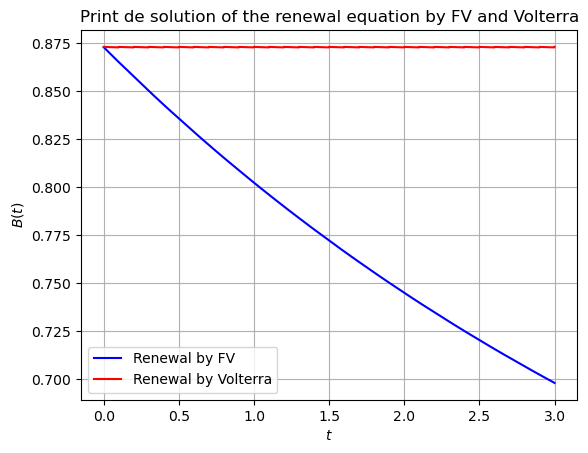

In [9]:
B_FV = np.loadtxt("renewal_B_FV.txt")
B_Volterra = np.loadtxt("renewal_B_Volterra.txt")

plt.plot(B_FV[:,0], B_FV[:,1], color = 'blue', label="Renewal by FV")
plt.plot(B_Volterra[:,0], B_Volterra[:,1], color = 'red', label="Renewal by Volterra")
plt.xlabel("$t$")
plt.ylabel("$B(t)$")
plt.title("Print de solution of the renewal equation by FV and Volterra")
plt.grid()
plt.legend()
plt.show()